# Evaluating quantum machine unlearning under data poisoning
**Phase 1 research workflow**

Muhammad Danish Zaheer, Ahmed Adil, and Sarmad Ali

This notebook follows the research from data preparation and clean baselines through poisoning, unlearning, and evaluation. The implemented stages cover data preparation, clean baselines, and poisoned-dataset preparation. The unpoisoned quantum model is our gold reference; poisoned-model training and unlearning will be added afterward. **Existing outputs are preserved. Newly added analysis cells have not been executed.**

Run the active sections in order. The circuit, every generated figure, and analysis tables appear here beside their interpretation notes. Section 8 also saves copies for the report. Later sections have empty code cells.

1. Research question
2. Environment and GPU check
3. Experiment settings
4. Data, fixed folds, and preprocessing
5. Classical baselines
6. Quantum circuit and forward check
7. Gold reference model: clean training and evaluation
8. Save outputs and discuss results
9. Poisoned-dataset preparation
10-15. Later work

## 1. Research question

Can Malik et al.'s distribution-guided, class-level unlearning method suppress digit 2 while preserving performance on digits 0 and 1 when the original model was trained on poisoned data?

**Motivation.** The method derives its forgetting and preservation targets from the trained model. Poisoning could affect those targets as well as the model. Chen and Zhang motivate studying poisoning and unlearning together, but their task removes known corrupted records; ours forgets a whole class.

**Working hypothesis.** Poisoning can weaken the trade-off between forgetting digit 2 and retaining digits 0/1, relative to clean training. We will separate damage already present after poisoned training from changes caused by unlearning.

**What could contradict this?** If paired clean/poisoned runs show no consistent deterioration in forgetting, retention, or agreement with matched retraining across the planned rates and seeds, the hypothesis is not supported in those conditions. Exact zero class-2 probability is not required.

The clean baselines check the data pipeline and model. The poisoning and unlearning experiments are needed to answer the full research question; clean accuracy alone cannot establish quantum advantage.

References: [Malik et al., supplied v2](Relevant_Papers/2601.04413v2.pdf) and [Chen and Zhang, supplied manuscript](Relevant_Papers/s41467-026-70420-4_reference.pdf). Our circuit is independently implemented from the paper; the private repository has not been used.

## 2. Environment and GPU check
### 2.1. Select the Python environment

Select the environment containing the packages in `requirements.txt`. Open this notebook from the project folder. Relative paths allow the folder to move from Windows to Linux.

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src" / "config.py").is_file():
    raise RuntimeError("Open this notebook with QML_Project as the working directory.")

print("Project:", PROJECT_ROOT)
print("Python:", sys.executable)

Project: C:\Users\DanishZaheer\Desktop\LUMS\Semester_3\QML\QML_Project
Python: c:\Users\DanishZaheer\anaconda3\envs\QML\python.exe


### 2.2. Check the physical GPU and Aer support

These are separate checks. `nvidia-smi` reports a visible NVIDIA GPU; `aer_devices` reports what the installed Aer build exposes. A missing NVIDIA report can also mean that `nvidia-smi` is unavailable. Actual simulator execution is checked in Section 6.

In [2]:
from src.artifacts import environment_info

environment = environment_info()
gpu_available_to_aer = "GPU" in environment["aer_devices"]

print("Operating system:", environment["platform"])
print("NVIDIA report:", environment["nvidia_gpu"] or "Not available")
print("Aer devices:", environment["aer_devices"])
print("Aer GPU advertised:", gpu_available_to_aer)

if not gpu_available_to_aer:
    print("This Aer environment will use CPU. Local simulation is still available.")

Operating system: Windows-11-10.0.26300-SP0
NVIDIA report: NVIDIA GeForce RTX 3060 Laptop GPU, 6144 MiB, 610.88
Aer devices: ['CPU']
Aer GPU advertised: False
This Aer environment will use CPU. Local simulation is still available.


**Interpretation.** An RTX GPU together with only `CPU` in Aer means this Aer environment does not expose GPU execution. Moving the folder alone will not enable it.

WSL2 is a possible route: configure compatible CUDA/driver support and a Linux Python environment with GPU-enabled Aer, then select its notebook kernel and repeat the check. Aer documents its prebuilt GPU package for x86-64 Linux; Microsoft documents CUDA access in WSL2. See the [Aer installation guide](https://qiskit.github.io/qiskit-aer/getting_started.html) and [Microsoft WSL CUDA guide](https://learn.microsoft.com/en-us/windows/ai/directml/gpu-cuda-in-wsl). This notebook does not install or move anything. A GPU is not automatically faster for a six-qubit circuit.

### 2.3. Import the notebook tools

Reusable algorithms remain in `src/`. This notebook calls them and displays their outputs.

In [3]:
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.config import DEFAULT_SEED, DataConfig, CircuitConfig, BackendConfig, TrainingConfig
from src.artifacts import save_split_manifest, load_json, save_json, fingerprint
from src.data.preprocessing import prepare_fold_features
from src.experiments import run_classical_cv, run_clean_vqc

display(pd.Series(environment["packages"], name="Installed version").to_frame())
figures = {}  # Keep figure objects for export in Section 8.

,Installed version
qiskit,2.5.1
qiskit-aer,0.17.2
qiskit-ibm-runtime,0.48.0
numpy,2.5.2
scipy,1.18.1
scikit-learn,1.9.1
pandas,3.1.0
matplotlib,3.11.1
joblib,1.6.0


## 3. Experiment settings
### 3.1. Fix the protocol before inspecting test results

| Choice | Initial protocol |
|---|---|
| Data | MNIST 0/1/2; 100 records per digit from the official training pool |
| Splits | Five fixed stratified outer folds; 20% of each outer training partition is validation |
| Features | Pixels divided by 255, four training-fitted PCA components, angles in [0, pi] |
| Classical models | Majority, logistic regression, linear SVM, RBF SVM on all five folds |
| Quantum model | Six qubits, two reuploads, three ansatz repetitions per reupload, 72 nominal weights |
| Quantum run | One clean run on fold 0, seed 6304 |
| Simulator | Local Aer, 2,048 shots, no device-noise model |
| Training | 300 mini-batch updates, batch size 10, Adam with a cosine learning rate |

The official MNIST test pool remains unused. Each outer test fold is held out from fitting and checkpoint selection. Default counts per fold are 192 training, 48 validation, and 60 test records.

This adapts Malik's circuit to MNIST and finite shots. Malik reports exact noiseless expectations. The sample size and incompletely specified optimizer settings are our starting choices, not reproduced paper settings.

### 3.2. Control downloading and training

`DOWNLOAD_MNIST=True` allows downloading when the loading cell is executed; an existing archive is verified and reused.

`RUN_QUANTUM_TRAINING=True` enables one clean gold VQC on `data_config.fold`, using `SEED`. With `REUSE_SAVED_RUNS=True`, an identical completed run is loaded if available; otherwise Section 7 trains and saves the model. Set the training flag to `False` to inspect saved results without starting fresh quantum training.

`REUSE_SAVED_RUNS=False` creates a fresh attempt. Keep reuse enabled to avoid repeating a completed matching run.

Restart the kernel and run Sections 2-8 in order when ready. Editing this flag does not execute the training cell or update an already-running kernel. Section 9 prepares poisoned data separately; poisoned-model training remains empty.

The fixed project seed is **6304**, defined once as `DEFAULT_SEED` in `src/config.py`. Data selection/splits, PCA, classical models, quantum initialization/training, and poisoning all use it. Existing saved outputs may show the previous seed; restart the kernel and rerun the active sections to generate matching results. Old run files keep their original provenance.


In [4]:
SEED = DEFAULT_SEED  # Fixed project seed: 6304.
DOWNLOAD_MNIST = True
RUN_QUANTUM_TRAINING = True  # Train one clean gold model on the selected fold.
REUSE_SAVED_RUNS = True

In [5]:
data_config = DataConfig(
    train_per_class=100,
    test_per_class=None,  # Unused: outer test folds come from the selected pool.
    split_strategy="stratified_kfold",
    n_folds=5,
    fold=0,
    validation_fraction=0.2,
    seed=SEED,
)

### 3.3. Configure local simulation and optimization

`device="auto"` uses GPU when Aer exposes it, otherwise CPU. GPU execution failures can fall back to CPU and are recorded. The 4,096 MB memory limit leaves headroom on the 6 GB laptop GPU; it is a simulator limit, not a GPU-memory reservation.

Finite shots introduce sampling variation even with zero device-error rates. IBM execution stays disabled.

In [6]:
circuit_config = CircuitConfig(reuploads=2, ansatz_reps=3)

backend_config = BackendConfig(
    shots=2048,
    device="auto",
    method="statevector",
    circuit_batch_size=128,
    max_memory_mb=4096,
    max_parallel_threads=4,
    allow_cpu_fallback=True,
    use_ibm_hardware=False,
)

In [7]:
training_config = TrainingConfig(
    steps=300,             # One step is a mini-batch update, not an epoch.
    batch_size=10,
    learning_rate=0.02,
    minimum_learning_rate=0.001,
    initialization_std=0.1,
    evaluate_every=10,
    patience=None,         # Keep the full declared budget.
)

## 4. Data, fixed folds, and preprocessing
### 4.1. Load the original data

The loader checks the MNIST archive checksum and selects digits 0/1/2. Raw downloads go to `data/raw/`. Every image retains its original sample ID so later poisoning and forgetting can be traced.

In [8]:
from src.data.dataset import load_mnist, balanced_subset, make_cv_splits

train_pool, official_test_pool = load_mnist(
    PROJECT_ROOT / "data" / "raw", download=DOWNLOAD_MNIST,
)
pool = balanced_subset(train_pool, per_class=data_config.train_per_class, seed=data_config.seed)

print("Selected development pool:", len(pool))
print("Official test records reserved and unused:", len(official_test_pool))
display(pd.Series(pool.labels).value_counts().sort_index().rename("Records").to_frame())

Selected development pool: 300
Official test records reserved and unused: 3147


,Records
0,100
1,100
2,100


### 4.2. Create and save fixed folds

Stratification keeps digit proportions similar across partitions. Validation selects the quantum checkpoint; the outer test fold is evaluated afterward. Save partition IDs so later experiments use the same records.

In [9]:
folds = make_cv_splits(
    pool,
    n_folds=data_config.n_folds,
    validation_fraction=data_config.validation_fraction,
    seed=data_config.seed,
)
split_files = [
    save_split_manifest(fold, PROJECT_ROOT / "data" / "splits")
    for fold in folds
]
splits = folds[data_config.fold]
print("Saved split manifests:", len(split_files))

Saved split manifests: 5


### 4.3. Check membership and class counts

Every selected record should appear in exactly one outer test fold. Within each fold, train/validation/test IDs must be disjoint. These checks stop execution if partitions are inconsistent.

In [10]:
outer_test_ids = np.concatenate([fold.test.sample_ids for fold in folds])
assert len(np.unique(outer_test_ids)) == len(outer_test_ids) == len(pool)
assert set(outer_test_ids) == set(pool.sample_ids)

for fold in folds:
    train_ids = set(fold.train.sample_ids)
    validation_ids = set(fold.validation.sample_ids)
    test_ids = set(fold.test.sample_ids)
    assert train_ids.isdisjoint(validation_ids)
    assert train_ids.isdisjoint(test_ids)
    assert validation_ids.isdisjoint(test_ids)

print("Split membership checks passed.")

Split membership checks passed.


In [11]:
split_rows = []
for fold_index, fold in enumerate(folds):
    for partition_name in ("train", "validation", "test"):
        partition = getattr(fold, partition_name)
        counts = np.bincount(partition.labels, minlength=3)
        split_rows.append({
            "fold": fold_index, "partition": partition_name, "total": len(partition),
            "digit_0": counts[0], "digit_1": counts[1], "digit_2": counts[2],
        })

split_table = pd.DataFrame(split_rows)
display(split_table)

,fold,partition,total,digit_0,digit_1,digit_2
0,0,train,192,64,64,64
1,0,validation,48,16,16,16
2,0,test,60,20,20,20
3,1,train,192,64,64,64
4,1,validation,48,16,16,16
5,1,test,60,20,20,20
6,2,train,192,64,64,64
7,2,validation,48,16,16,16
8,2,test,60,20,20,20
9,3,train,192,64,64,64


### 4.4. Inspect training examples and the selected fold

The examples come only from the selected fold's training partition. Check that image content matches the labels and that all three digits are represented.

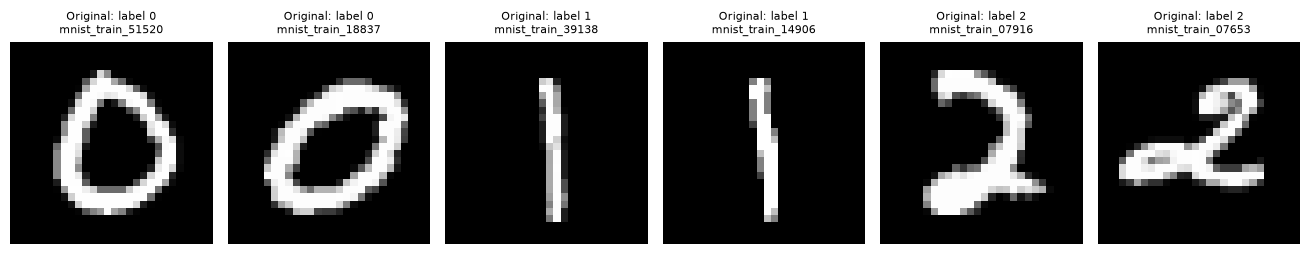

In [12]:
from src.evaluation.plots import (
    plot_examples, plot_class_balance, plot_pca_variance,
    plot_training_history, draw_circuit, save_figure,
)

example_indices = np.concatenate([
    np.flatnonzero(splits.train.labels == digit)[:2] for digit in (0, 1, 2)
])
figure = plot_examples(splits.train, indices=example_indices)
figures["training_examples"] = figure
display(figure)
plt.close(figure)

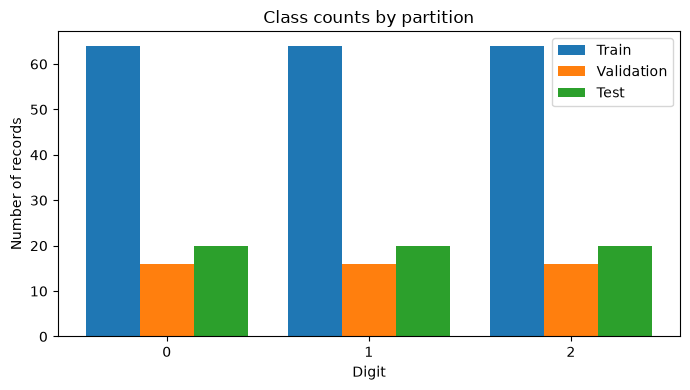

In [13]:
figure = plot_class_balance({
    "Train": splits.train.labels,
    "Validation": splits.validation.labels,
    "Test": splits.test.labels,
})
figures["selected_fold_counts"] = figure
display(figure)
plt.close(figure)

### 4.5. Fit preprocessing using training records only

The helper divides pixels by 255, fits four PCA components, and fits an angle scaler. Validation/test images only use `transform`. Values outside the fitted range are clipped to [0, pi].

Each fold gets a separate transformer. Classical and quantum models on the same fold use the same fitting rule, records, and seed.

In [14]:
fold_features = prepare_fold_features(splits, seed=data_config.seed)
preprocessing = fold_features["preprocessing"]

X_train = fold_features["train"]
X_validation = fold_features["validation"]
X_test = fold_features["test"]

assert set(preprocessing.fit_sample_ids_) == set(splits.train.sample_ids)
assert X_train.shape == (len(splits.train), 4)
assert all(np.isfinite(values).all() for values in (X_train, X_validation, X_test))
print("Feature shapes:", X_train.shape, X_validation.shape, X_test.shape)

Feature shapes: (192, 4) (48, 4) (60, 4)


,angle_0,angle_1,angle_2,angle_3
0,2.878200,0.153736,1.816863,2.552748
1,0.988830,0.861512,2.795519,1.538018
2,0.632573,0.119700,1.352035,1.045870
3,2.901533,0.183729,1.801898,2.718371
4,3.103146,1.040459,1.523216,0.869256


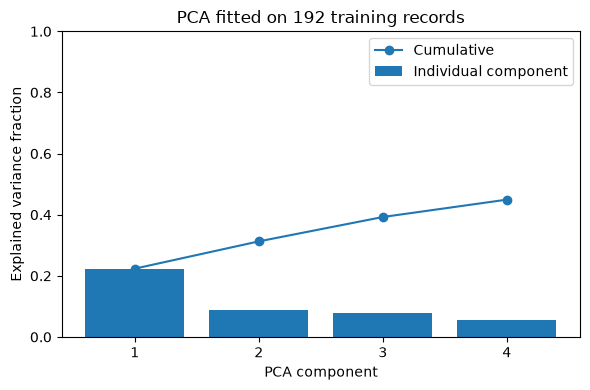

In [15]:
display(pd.DataFrame(X_train[:5], columns=["angle_0", "angle_1", "angle_2", "angle_3"]))

figure = plot_pca_variance(preprocessing)
figures["pca_variance"] = figure
display(figure)
plt.close(figure)

### 4.6. Quantify the retained variance

The table gives the fraction of training-pixel variance explained by each PCA component and the cumulative fraction shown in the plot above. These numbers describe compression of this fold's training data.


In [16]:
variance_ratio = preprocessing.pca.explained_variance_ratio_
pca_variance_table = pd.DataFrame({
    "component": np.arange(1, len(variance_ratio) + 1),
    "explained_variance_ratio": variance_ratio,
    "cumulative_variance_ratio": np.cumsum(variance_ratio),
})
display(pca_variance_table.round(4))


,component,explained_variance_ratio,cumulative_variance_ratio
0,1,0.2235,0.2235
1,2,0.0893,0.3127
2,3,0.0797,0.3924
3,4,0.0569,0.4493


**Interpretation.** The PCA plot shows training-pixel variation retained in four components. High explained variance does not guarantee good classification. If classical models also perform poorly, the representation or sample budget may be a limitation. Use training/validation evidence for later changes, rather than tuning to test results.

## 5. Classical baselines
### 5.1. Fit four comparison models on all five folds

All models receive the same four features as the VQC. The majority model provides a basic reference. Logistic regression, linear SVM, and RBF SVM test whether the representation contains useful class information.

Hyperparameters are fixed in `src/models/classical.py`. SVM probabilities use internal calibration within the training partition; predictions use the largest class probability. Outer validation/test records never enter fitting or calibration. Models, preprocessing, predictions, and metrics are saved together.

In [17]:
classical_run = run_classical_cv(
    folds, data_config=data_config, seed=SEED,
    reuse=REUSE_SAVED_RUNS, root=PROJECT_ROOT,
)
baseline_scores = pd.read_csv(classical_run["path"] / "scores.csv")
print("Classical run:", classical_run["path"].relative_to(PROJECT_ROOT))

Classical run: results\runs\classical_cv\none_p0_seed6304_fold0_48930b7fd2954462


### 5.2. Summarize classical results

Accuracy is the fraction of correct three-class predictions. Standard deviation below describes variation across fixed folds at one seed. It is not uncertainty across independent seeds or a confidence interval.

In [18]:
# Inspect each fold before averaging: model rankings may vary by split.
fold_accuracy = baseline_scores.pivot(index="fold", columns="model", values="accuracy")
display(fold_accuracy.round(3))


model,linear_svm,logistic,majority,rbf_svm
fold,,,,
0,0.933,0.950,0.333,0.933
1,0.950,0.967,0.333,0.967
2,0.967,0.950,0.333,0.967
3,0.917,0.933,0.333,0.933
4,0.950,0.917,0.333,0.950


In [19]:
classical_summary = baseline_scores.groupby("model").agg(
    mean_accuracy=("accuracy", "mean"),
    fold_sd=("accuracy", "std"),
    n_folds=("fold", "nunique"),
)
display(classical_summary.round(3))

,mean_accuracy,fold_sd,n_folds
model,,,
linear_svm,0.943,0.019,5
logistic,0.943,0.019,5
majority,0.333,0.000,5
rbf_svm,0.950,0.017,5


**Interpretation to complete after execution.** Which models improve over the majority reference? Are fold differences large? Strong classical performance is useful evidence about the representation. Report weak or unfavorable quantum results too.

## 6. Quantum circuit and forward check
### 6.1. Build the circuit from Malik et al.

Two feature-map/ansatz blocks act on six qubits. Four features enter the first four qubits. Each ansatz has three repetitions of trainable RY/RZ rotations and ring CNOTs. Z expectations on qubits 3/4/5 become logits for a three-class softmax.

There are 72 nominal trainable weights and four input symbols. The final six RZ angles are inactive for the ideal Z readout; they remain to preserve the reported architecture. These are constructed-circuit counts; compiled resources are saved with the training run.
The full parameterized circuit is drawn below, wrapped across rows for readability. Follow the wire labels between rows. The gate table counts operations before transpilation; it does not measure hardware noise or execution time.


In [20]:
from src.models.circuits import build_malik_circuit, circuit_resources

circuit = build_malik_circuit(circuit_config)
circuit_information = circuit_resources(circuit)
display(pd.Series({
    "qubits": circuit_information["qubits"],
    "depth_before_transpilation": circuit_information["depth"],
    "two_qubit_gates": circuit_information["two_qubit_gates"],
    "nominal_trainable_weights": circuit_config.n_parameters,
    "input_features": 4,
}, name="Value").to_frame())

,Value
qubits,6
depth_before_transpilation,66
two_qubit_gates,48
nominal_trainable_weights,72
input_features,4


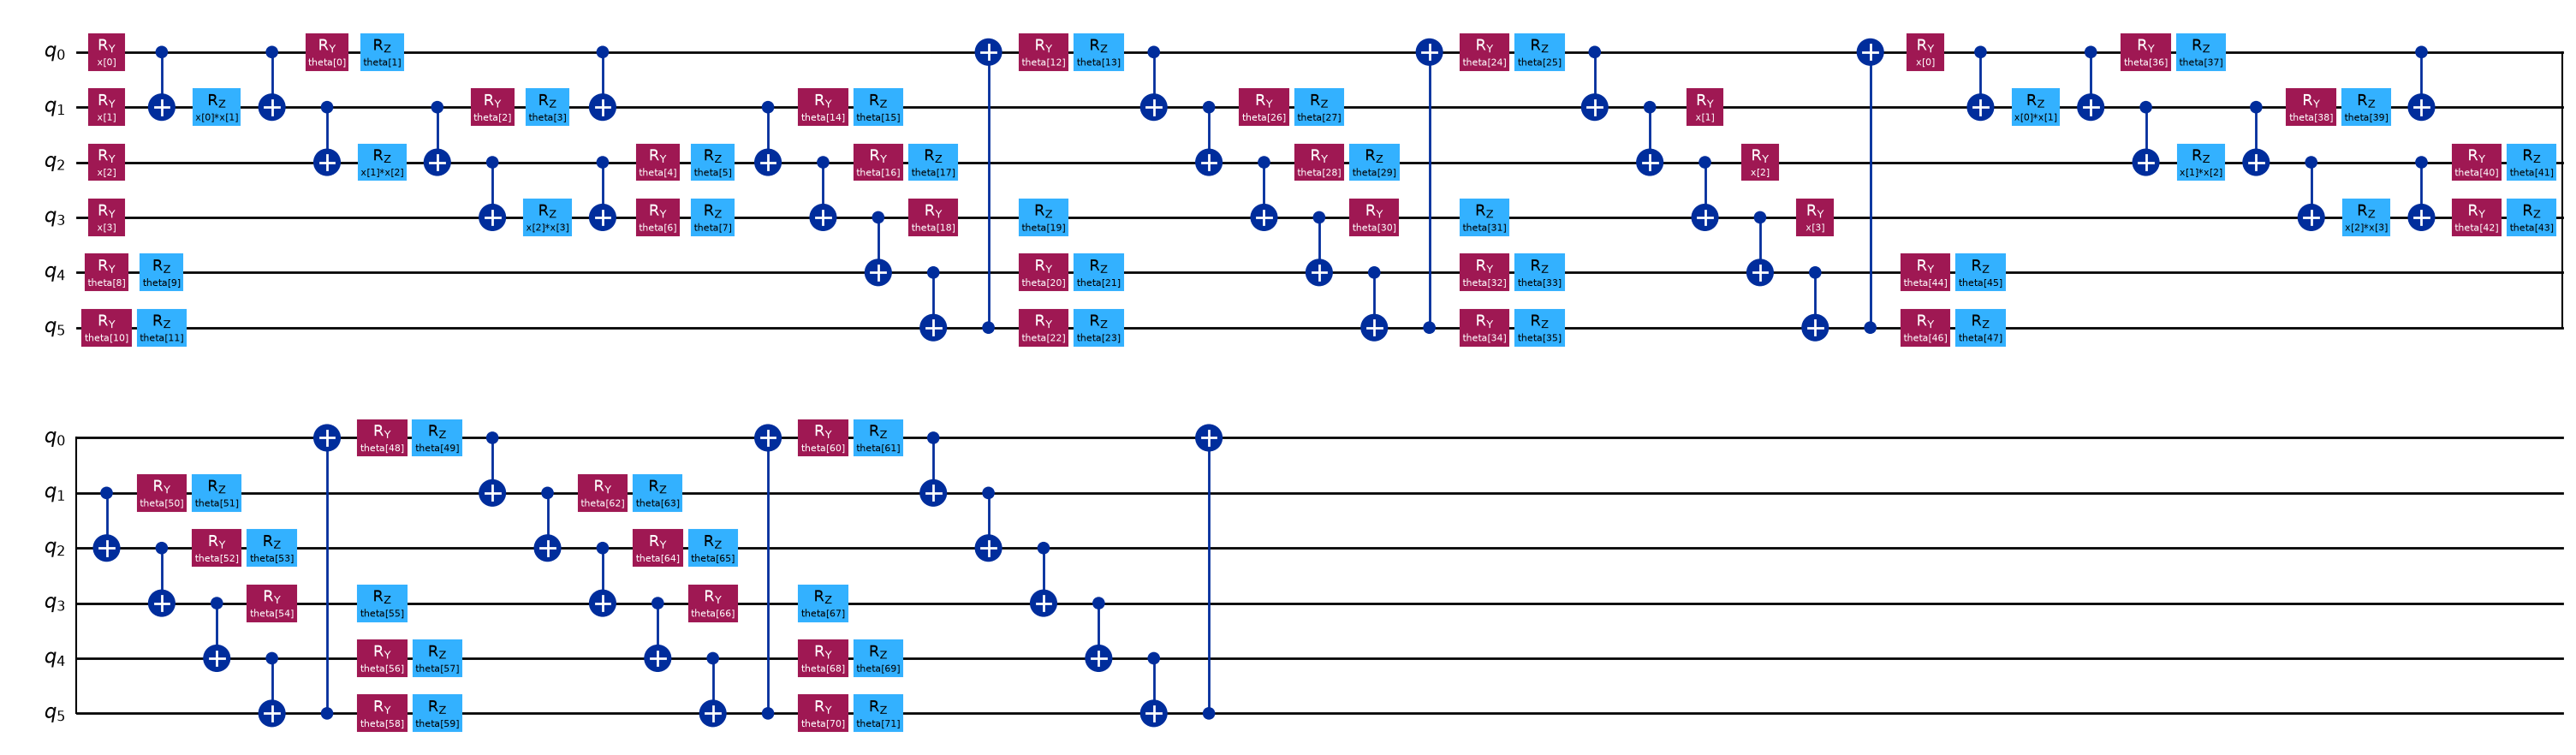

In [21]:
figure = draw_circuit(circuit, fold=45)
figures["quantum_circuit"] = figure
display(figure)
plt.close(figure)

In [22]:
gate_counts = pd.Series(
    circuit_information["operations"], name="count",
).rename_axis("gate").sort_index().to_frame()
display(gate_counts)


,count
gate,
cx,48
ry,44
rz,42


### 6.2. Check a small prediction batch

These are untrained random-weight predictions, not a trained-model result. Each row must contain three finite probabilities summing to one. This call also checks actual Aer execution.

The probe is separate from the training model so its samples do not consume the training run's random stream.

In [23]:
from src.models.vqc import VQC

probe_model = VQC(circuit_config, backend_config, seed=SEED)
initial_weights = np.random.default_rng(SEED).normal(
    0.0, training_config.initialization_std, circuit_config.n_parameters,
)
probe_probabilities = probe_model.predict_proba(X_train[:3], initial_weights)

assert np.isfinite(probe_probabilities).all()
assert np.all(probe_probabilities >= 0) and np.all(probe_probabilities <= 1)
assert np.allclose(probe_probabilities.sum(axis=1), 1.0)
display(pd.DataFrame(probe_probabilities, columns=["p(0)", "p(1)", "p(2)"]))

,p(0),p(1),p(2)
0,0.395675,0.277578,0.326747
1,0.348249,0.343520,0.308231
2,0.338094,0.336447,0.325459


In [24]:
probe_resources = probe_model.metadata()
print("Probe execution device:", probe_resources["actual_device"])
print("Probe expectation mode:", probe_resources["expectation_mode"])
print("Fallback reason:", probe_resources["fallback_reason"] or "None")

Probe execution device: CPU
Probe expectation mode: sampled
Fallback reason: None


### 6.3. Understand the training budget

The gradient shifts expectation values, then applies the classical softmax/cross-entropy chain rule. It does not shift the complete nonlinear loss.

Each gradient uses 1 + 2 x 72 circuit bindings per training example. This estimate excludes additional full training/validation checks and final test evaluation. Finite-shot training can take substantial time even for six qubits.

In [25]:
bindings_per_example = 1 + 2 * circuit_config.n_parameters
batch_size = min(training_config.batch_size, len(splits.train))
gradient_bindings = training_config.steps * batch_size * bindings_per_example

print(f"Gradient circuit bindings: {gradient_bindings:,}")
print(f"Gradient shot budget: {gradient_bindings * backend_config.shots:,}")
print("Additional evaluations are included in the saved resource counters.")

Gradient circuit bindings: 435,000
Gradient shot budget: 890,880,000
Additional evaluations are included in the saved resource counters.


## 7. Gold reference model: clean training and evaluation
### 7.1. Train one gold reference on clean data

Quantum training is enabled in Section 3. This section calls `run_clean_vqc` once for the selected fold and seed. With the current settings, this is fold 0 and seed 6304. The classical baselines cover five folds; the quantum gold reference currently covers one.

Adam updates the weights using training mini-batches. Validation loss selects the checkpoint, including initialization if it remains best. The clean test partition evaluates the selected checkpoint after training.

The gold reference learns digits 0, 1, and 2 using original, unpoisoned training images and labels. Its weights, history, predictions, and settings are saved under `results/runs/clean_vqc/`. Matching completed runs are reused. Poisoned-model training and retained-data retraining remain later work.


In [26]:
def show_training_progress(row):
    # Every evaluation is saved; print only a few updates here.
    step = int(row["step"])
    if step % 50 == 0 or step == training_config.steps:
        print(
            f"Update {step:3d} | train loss {row['train_loss']:.4f} | "
            f"validation loss {row['validation_loss']:.4f}"
        )

In [27]:
# Confirm the one-model training plan before the training call.
assert splits.fingerprint() == folds[data_config.fold].fingerprint()
print(f"Gold reference: one clean VQC; fold {data_config.fold}; seed {SEED}.")
print(f"Records: {len(splits.train)} train, {len(splits.validation)} validation, {len(splits.test)} test.")
print(f"Budget: {training_config.steps} updates; batch size {training_config.batch_size}; {backend_config.shots} shots.")
print(f"Local Aer device preference: {backend_config.device}; reuse matching run: {REUSE_SAVED_RUNS}.")


Gold reference: one clean VQC; fold 0; seed 6304.
Records: 192 train, 48 validation, 60 test.
Budget: 300 updates; batch size 10; 2048 shots.
Local Aer device preference: auto; reuse matching run: True.


In [28]:
quantum_run = run_clean_vqc(
    splits, data_config=data_config,
    circuit_config=circuit_config, backend_config=backend_config,
    training_config=training_config, seed=SEED,
    allow_training=RUN_QUANTUM_TRAINING,
    reuse=REUSE_SAVED_RUNS, callback=show_training_progress,
    root=PROJECT_ROOT,
)

Update   0 | train loss 1.1170 | validation loss 1.1092
Update  50 | train loss 0.8938 | validation loss 0.8865
Update 100 | train loss 0.8561 | validation loss 0.8458
Update 150 | train loss 0.8394 | validation loss 0.8287
Update 200 | train loss 0.8334 | validation loss 0.8253
Update 250 | train loss 0.8277 | validation loss 0.8169
Update 300 | train loss 0.8299 | validation loss 0.8187


In [29]:
# Clear old quantum plots if this section is rerun without a matching result.
for name in ("quantum_learning_curve", "quantum_confusion"):
    figures.pop(name, None)

if quantum_run is None:
    print("No matching quantum result. Enable RUN_QUANTUM_TRAINING and rerun Section 7 onward.")
else:
    print("Quantum run:", quantum_run["path"].relative_to(PROJECT_ROOT))
    print("Selected update:", quantum_run["manifest"]["best_step"])
    print("Best validation loss:", quantum_run["manifest"]["best_validation_loss"])

Quantum run: results\runs\clean_vqc\none_p0_seed6304_fold0_96fbe76aa35bb715
Selected update: 290
Best validation loss: 0.8162741611239772


### 7.2. Inspect the learning curve

Training loss reflects fit to training examples; validation loss selects the checkpoint. Falling training loss with rising validation loss can indicate overfitting. Flat curves can indicate an optimization or capacity limitation. Finite-shot losses can fluctuate.
The table compares initialization, the checkpoint selected by validation loss, and the final recorded update. Two rows may refer to the same update. The loss gap is validation minus training loss; interpret it alongside the curves and finite-shot fluctuations. Test performance never selects these rows.


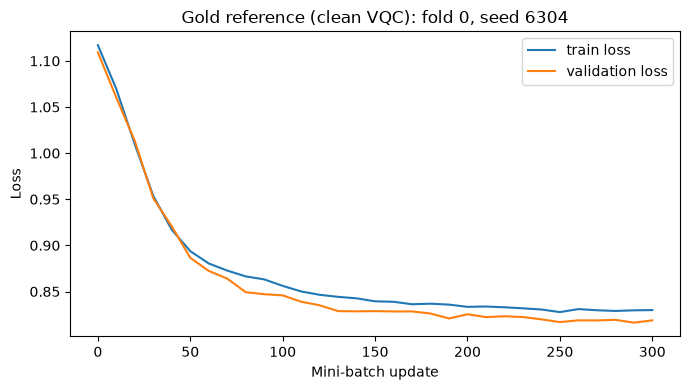

In [30]:
if quantum_run is not None:
    figure = plot_training_history(
        quantum_run["history"],
        title=f"Gold reference (clean VQC): fold {data_config.fold}, seed {SEED}",
    )
    figures["quantum_learning_curve"] = figure
    display(figure)
    plt.close(figure)

In [31]:
checkpoint_table = pd.DataFrame()
if quantum_run is not None:
    history = quantum_run["history"].set_index("step")
    selected_steps = [0, quantum_run["manifest"]["best_step"], history.index[-1]]
    checkpoint_table = history.loc[
        selected_steps, ["train_loss", "validation_loss", "elapsed_seconds"]
    ].copy()
    checkpoint_table.insert(0, "checkpoint", ["initial", "selected", "final"])
    checkpoint_table["validation_minus_train_loss"] = (
        checkpoint_table["validation_loss"] - checkpoint_table["train_loss"]
    )
    display(checkpoint_table.round(4))


,checkpoint,train_loss,validation_loss,elapsed_seconds,validation_minus_train_loss
step,,,,,
0,initial,1.1170,1.1092,0.6357,-0.0078
290,selected,0.8296,0.8163,1114.4241,-0.0133
300,final,0.8299,0.8187,1151.7938,-0.0111


### 7.3. Compare on the same held-out records

Compare the first VQC with classical models on this same fold, rather than comparing its single score with a five-fold average.

Values are fractions from 0 to 1. Retained accuracy uses true digits 0/1 with normal three-class predictions. Digit-2 recall measures correct classification of digit 2. Before unlearning, high digit-2 recall is desirable: the model needs learned behavior to forget later.

In [32]:
comparison_columns = ["model", "n_test", "accuracy", "retained_accuracy", "digit_2_recall"]
same_fold_comparison = baseline_scores.loc[
    baseline_scores["fold"] == data_config.fold, comparison_columns
].copy()

In [33]:
if quantum_run is not None:
    quantum_metrics = quantum_run["metrics"]["models"]["clean"]
    quantum_row = {
        "model": "gold_reference", "n_test": quantum_metrics["n_samples"],
        "accuracy": quantum_metrics["accuracy"],
        "retained_accuracy": quantum_metrics["retained_accuracy"],
        "digit_2_recall": quantum_metrics["forget_recall"],
    }
    same_fold_comparison = pd.concat(
        [same_fold_comparison, pd.DataFrame([quantum_row])], ignore_index=True,
    )

display(same_fold_comparison.round(3))

,model,n_test,accuracy,retained_accuracy,digit_2_recall
0,majority,60,0.333,0.500,0.0
1,logistic,60,0.950,0.975,0.9
2,linear_svm,60,0.933,0.950,0.9
3,rbf_svm,60,0.933,0.950,0.9
4,gold_reference,60,0.833,0.900,0.7


### 7.4. Compare errors for each digit

Overall accuracy can hide a weak class. Compare all models on the same held-out fold: `n_test` is the number of examples of that true digit, `correct` and `errors` are counts, and `recall` is the fraction classified correctly. The gold reference appears only when its saved result exists.

Use this table to identify which digit is difficult and whether digit 2 is learned before any forgetting request. A difference of one or two examples in this small fold is limited evidence; report the counts alongside recall.


In [34]:
# Copy the saved metrics so this analysis does not alter the run records.
comparison_metrics = dict(classical_run["metrics"]["folds"][str(data_config.fold)])
if quantum_run is not None:
    comparison_metrics["gold_reference"] = quantum_metrics


In [35]:
class_rows = []
for model_name, metrics in comparison_metrics.items():
    confusion = np.asarray(metrics["confusion_matrix"])
    for digit in range(3):
        support = int(confusion[digit].sum())
        correct = int(confusion[digit, digit])
        class_rows.append({
            "model": model_name, "digit": digit, "n_test": support,
            "correct": correct, "errors": support - correct,
            "recall": metrics["recall_by_class"][str(digit)],
        })
per_class_comparison = pd.DataFrame(class_rows)
display(per_class_comparison.round(3))


,model,digit,n_test,correct,errors,recall
0,linear_svm,0,20,19,1,0.95
1,linear_svm,1,20,19,1,0.95
2,linear_svm,2,20,18,2,0.90
3,logistic,0,20,19,1,0.95
4,logistic,1,20,20,0,1.00
5,logistic,2,20,18,2,0.90
6,majority,0,20,20,0,1.00
7,majority,1,20,0,20,0.00
8,majority,2,20,0,20,0.00
9,rbf_svm,0,20,18,2,0.90


### 7.5. Inspect the quantum confusion matrix

Rows are true digits; columns are predicted digits. Diagonal entries are correct predictions. Check whether the model recognizes all three digits or mainly predicts one class. This plot appears only when a quantum result exists.

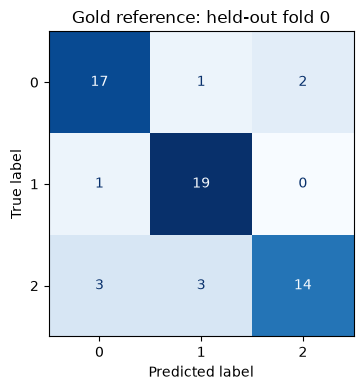

In [36]:
from sklearn.metrics import ConfusionMatrixDisplay

if quantum_run is not None:
    figure, axis = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay(
        np.asarray(quantum_metrics["confusion_matrix"]), display_labels=[0, 1, 2],
    ).plot(ax=axis, cmap="Blues", colorbar=False)
    axis.set_title(f"Gold reference: held-out fold {data_config.fold}")
    figure.tight_layout()
    figures["quantum_confusion"] = figure
    display(figure)
    plt.close(figure)

### 7.6. Record actual computation

Counters include training, full training/validation checks, and final test prediction. The separate probe is excluded. Training time excludes the final test call. Device and compiled-circuit details come from the saved run, including when reloaded.

In [37]:
resource_table = pd.DataFrame()
if quantum_run is not None:
    resources = load_json(quantum_run["path"] / "resources.json")
    resource_table = pd.DataFrame([{
        "device": resources["actual_device"],
        "method": resources["actual_method"],
        "qubits": resources["compiled_circuit"]["qubits"],
        "compiled_depth": resources["compiled_circuit"]["depth"],
        "two_qubit_gates": resources["compiled_circuit"]["two_qubit_gates"],
        "shots_per_circuit": resources["requested"]["shots"],
        "circuit_evaluations": resources["resources"]["circuit_evaluations"],
        "total_shots": resources["resources"]["shots"],
        "training_seconds": quantum_run["history"]["elapsed_seconds"].iloc[-1],
    }])
    display(resource_table)

,device,method,qubits,compiled_depth,two_qubit_gates,shots_per_circuit,circuit_evaluations,total_shots,training_seconds
0,CPU,statevector,6,67,48,2048,442500,906240000,1151.793833


## 8. Save outputs and discuss results
### 8.1. Export tables and figures

The helpers save settings, source/environment identity, record IDs, preprocessing, predictions, metrics, and model checkpoints in `results/runs/classical_cv/` and `results/runs/clean_vqc/`.

Every generated figure is displayed inline in its relevant section before export. The analysis tables are displayed there too. Export copies below so the same evidence is available for the report. PNG supports slides; PDF supports the report. Poisoned annotations are created in the poisoning stage.

In [38]:
source_runs = [classical_run["path"].relative_to(PROJECT_ROOT).as_posix()]
if quantum_run is not None:
    source_runs.append(quantum_run["path"].relative_to(PROJECT_ROOT).as_posix())

view_settings = {
    "source_runs": source_runs, "fold": data_config.fold,
    "circuit": asdict(circuit_config), "quantum_result_available": quantum_run is not None,
}
view_id = fingerprint(view_settings)[:16]
table_directory = PROJECT_ROOT / "results" / "tables" / view_id
figure_directory = PROJECT_ROOT / "results" / "figures" / view_id
table_directory.mkdir(parents=True, exist_ok=True)

In [39]:
split_table.to_csv(table_directory / "fixed_fold_counts.csv", index=False)
baseline_scores.to_csv(table_directory / "classical_fold_scores.csv", index=False)
classical_summary.to_csv(table_directory / "classical_summary.csv")
same_fold_comparison.to_csv(table_directory / "same_fold_comparison.csv", index=False)
if quantum_run is not None:
    resource_table.to_csv(table_directory / "quantum_resources.csv", index=False)

save_json(table_directory / "provenance.json", view_settings)
print("Tables:", table_directory.relative_to(PROJECT_ROOT))

Tables: results\tables\79ccc9816a2f798e


In [40]:
# Export the additional displayed analysis tables without rounding.
pca_variance_table.to_csv(table_directory / "pca_variance.csv", index=False)
gate_counts.to_csv(table_directory / "circuit_gate_counts.csv")
fold_accuracy.to_csv(table_directory / "classical_accuracy_by_fold.csv")
per_class_comparison.to_csv(table_directory / "per_class_comparison.csv", index=False)
if quantum_run is not None:
    checkpoint_table.to_csv(table_directory / "quantum_checkpoints.csv")


In [41]:
for name, figure in figures.items():
    save_figure(
        figure, figure_directory / name,
        source_run_ids=source_runs,
        description=f"Clean baseline: {name.replace('_', ' ')}; selected fold {data_config.fold}.",
    )

save_json(figure_directory / "provenance.json", view_settings)
print("Figures:", figure_directory.relative_to(PROJECT_ROOT))

Figures: results\figures\79ccc9816a2f798e


### 8.2. Discussion to complete after execution

- **Data:** did partition checks pass, and how much variance do four PCA components retain?
- **Classical models:** compare each fold before interpreting mean accuracy and fold standard deviation. Does the model ranking change across folds?
- **Gold reference:** compare initial, selected, and final losses. Record held-out accuracy and same-fold comparisons. Which digit has the most errors, and was digit 2 learned well enough to evaluate forgetting later?
- **Computation:** record actual device, shots, circuit evaluations, and training time.
- **Limitations:** one quantum fold/seed, a small selected dataset, finite shots, and no poisoning/unlearning results yet.
- **Next decision:** establish a usable clean baseline before interpreting forgetting. Investigate weak training using training/validation evidence.

**Discussion to complete from actual outputs.** Newly added analysis cells need execution. Include unfavorable or inconclusive findings, and leave quantum conclusions pending until a trained result is available. Section 1 and Sections 3-7 provide introduction/methods material for the research report. The LaTeX report and GitHub submission are separate tasks.

## 9. Prepare poisoned training datasets

This section prepares data only. It creates a clean control and separate pixel-patch and label-flip variants for the selected fold. Poisoned-model training remains in the empty Section 10.

Run Sections 2-4 first so the settings, original MNIST data, and fixed splits are available. Section 9 can run without training either the clean or poisoned models. It keeps images on their original 0-255 scale; fitting preprocessing for poisoned-model training comes later.

### 9.1. Set the poisoning conditions

Use 5%, 10%, and 20% of the **eligible training class**: digit 2 for pixel changes and digit 0 for label flips. These percentages differ from percentages of the whole training partition. Counts are rounded down; the tables below report both realized fractions. Small datasets may produce zero selected records.

The white 3-by-3 bottom-right patch is our configurable attack choice, not a pixel-level prescription reproduced from either paper. The same seed within each attack gives nested selected records as the rate increases.


In [42]:
from src.config import PoisonConfig
from src.data.poisoning import apply_poisoning
from src.artifacts import save_poisoned_dataset, source_fingerprint

POISON_RATES = (0.05, 0.10, 0.20)
POISON_SEED = SEED
POISON_RATE_DENOMINATOR = "eligible"
PATCH_SIZE = 3
PATCH_VALUE = 255.0

assert POISON_RATES and len(set(POISON_RATES)) == len(POISON_RATES)
assert all(0 < rate <= 1 for rate in POISON_RATES)
assert POISON_RATE_DENOMINATOR in ("eligible", "all_training")


### 9.2. Reuse the selected training fold

All variants start from the same original training records. Validation and test data remain clean. The clean control records the zero-poison condition using the same annotation format. Re-run Section 4 after changing dataset size or fold settings.


In [43]:
clean_training = splits.train
assert splits.fingerprint() == folds[data_config.fold].fingerprint()
clean_partition_fingerprints = {
    name: getattr(splits, name).fingerprint() for name in ("train", "validation", "test")
}
poison_variants = {
    "clean": apply_poisoning(clean_training, PoisonConfig(seed=POISON_SEED))
}
poison_figures = {}  # Separate from the clean-model figures in Section 8.
print(f"Preparing fold {data_config.fold}: {len(clean_training)} training records.")


Preparing fold 0: 192 training records.


### 9.3. Add pixel patches to digit 2

Only selected digit-2 training images receive the patch. Their labels remain 2. Each rate starts from the original images, so patches do not accumulate across variants.


In [44]:
for rate in sorted(POISON_RATES):
    condition = f"pixel_patch_{100 * rate:g}pct"
    poison_config = PoisonConfig(
        kind="pixel_patch", rate=rate, denominator=POISON_RATE_DENOMINATOR,
        seed=POISON_SEED, target_class=2,
        patch_size=PATCH_SIZE, patch_value=PATCH_VALUE,
    )
    poison_variants[condition] = apply_poisoning(clean_training, poison_config)


### 9.4. Flip selected digit-0 labels to digit 2

The images stay unchanged. Only the observed training label changes from 0 to 2; original labels and sample IDs are retained for auditing. Pixel patches and label flips are separate conditions.


In [45]:
for rate in sorted(POISON_RATES):
    condition = f"label_flip_{100 * rate:g}pct"
    poison_config = PoisonConfig(
        kind="label_flip", rate=rate, denominator=POISON_RATE_DENOMINATOR,
        seed=POISON_SEED, source_class=0, target_class=2,
    )
    poison_variants[condition] = apply_poisoning(clean_training, poison_config)


### 9.5. Check record alignment and intended changes

These assertions check the prepared data before saving: stable IDs, correct counts, unchanged unselected records, and the intended attack. A failed check stops the section. Fingerprints also check that preparing the variants did not modify the original training, validation, or test data.


In [46]:
for condition, variant in poison_variants.items():
    np.testing.assert_array_equal(variant.observed.sample_ids, clean_training.sample_ids)
    assert variant.original.fingerprint() == clean_partition_fingerprints["train"]
    unchanged = ~variant.is_poisoned
    np.testing.assert_array_equal(variant.observed.images[unchanged], clean_training.images[unchanged])
    np.testing.assert_array_equal(variant.observed.labels[unchanged], clean_training.labels[unchanged])
    denominator = (variant.eligible_count if variant.config.denominator == "eligible"
                   else len(clean_training))
    expected_count = int(np.floor(variant.config.rate * denominator))
    assert int(variant.is_poisoned.sum()) == expected_count, condition


In [47]:
for condition, variant in poison_variants.items():
    selected = variant.is_poisoned
    if variant.config.kind == "pixel_patch":
        np.testing.assert_array_equal(variant.observed.labels, clean_training.labels)
        assert np.all(clean_training.labels[selected] == 2)
        size = variant.config.patch_size
        assert np.all(variant.observed.images[selected, -size:, -size:] == variant.config.patch_value)
        changed_positions = np.any(variant.observed.images != clean_training.images, axis=0)
        changed_positions[-size:, -size:] = False
        assert not changed_positions.any(), condition
    elif variant.config.kind == "label_flip":
        np.testing.assert_array_equal(variant.observed.images, clean_training.images)
        assert np.all(clean_training.labels[selected] == 0)
        assert np.all(variant.observed.labels[selected] == 2)


In [48]:
for attack in ("pixel_patch", "label_flip"):
    previous_ids = set()
    for rate in sorted(POISON_RATES):
        variant = poison_variants[f"{attack}_{100 * rate:g}pct"]
        selected_ids = set(variant.observed.sample_ids[variant.is_poisoned])
        assert previous_ids <= selected_ids, "Expected nested selected records."
        previous_ids = selected_ids

for partition, expected_fingerprint in clean_partition_fingerprints.items():
    assert getattr(splits, partition).fingerprint() == expected_fingerprint, partition
print("Checks passed: intended changes only; original partitions remain unchanged.")


Checks passed: intended changes only; original partitions remain unchanged.


### 9.6. Inspect requested rates, actual changes, and label balance

`selected_records` counts records chosen for the attack. `changed_images` counts actual pixel changes: a patch can have no effect if those pixels already equal the requested value. Label flips should change labels without changing images; pixel patches should preserve label counts.


In [49]:
poison_summary_rows = []
for condition, variant in poison_variants.items():
    information = variant.metadata()
    poison_summary_rows.append({
        "variant": condition, "n_training": len(clean_training),
        "eligible_records": information["eligible_count"],
        "selected_records": information["poisoned_count"],
        "requested_pct": 100 * variant.config.rate,
        "actual_eligible_pct": 100 * information["actual_fraction_eligible"],
        "actual_training_pct": 100 * information["actual_fraction_all_training"],
    })
poison_summary = pd.DataFrame(poison_summary_rows)
display(poison_summary.round(3))


,variant,n_training,eligible_records,selected_records,requested_pct,actual_eligible_pct,actual_training_pct
0,clean,192,64,0,0.0,0.000,0.000
1,pixel_patch_5pct,192,64,3,5.0,4.688,1.562
2,pixel_patch_10pct,192,64,6,10.0,9.375,3.125
3,pixel_patch_20pct,192,64,12,20.0,18.750,6.250
4,label_flip_5pct,192,64,3,5.0,4.688,1.562
5,label_flip_10pct,192,64,6,10.0,9.375,3.125
6,label_flip_20pct,192,64,12,20.0,18.750,6.250


In [50]:
change_rows = []
for condition, variant in poison_variants.items():
    changed_images = np.any(variant.observed.images != clean_training.images, axis=(1, 2))
    changed_labels = variant.observed.labels != clean_training.labels
    change_rows.append({
        "variant": condition, "changed_images": int(changed_images.sum()),
        "changed_labels": int(changed_labels.sum()),
        "selected_without_change": int((variant.is_poisoned & ~changed_images & ~changed_labels).sum()),
    })
poison_changes = pd.DataFrame(change_rows)
display(poison_changes)


,variant,changed_images,changed_labels,selected_without_change
0,clean,0,0,0
1,pixel_patch_5pct,3,0,0
2,pixel_patch_10pct,6,0,0
3,pixel_patch_20pct,12,0,0
4,label_flip_5pct,0,3,0
5,label_flip_10pct,0,6,0
6,label_flip_20pct,0,12,0


In [51]:
poison_label_counts = pd.DataFrame({
    condition: np.bincount(variant.observed.labels, minlength=3)
    for condition, variant in poison_variants.items()
}).T.rename_axis("variant").rename(columns={0: "digit_0", 1: "digit_1", 2: "digit_2"})
display(poison_label_counts)


,digit_0,digit_1,digit_2
variant,,,
clean,64,64,64
pixel_patch_5pct,64,64,64
pixel_patch_10pct,64,64,64
pixel_patch_20pct,64,64,64
label_flip_5pct,61,64,67
label_flip_10pct,58,64,70
label_flip_20pct,52,64,76


### 9.7. View clean and poisoned examples

Preview both attacks at the largest configured rate. Change `PREVIEW_RATE` to another configured rate to inspect it. Each column follows the same record before and after the change. These examples verify the data construction; they do not establish model damage or robustness.


In [52]:
from src.evaluation.plots import plot_examples, plot_class_balance, save_figure

PREVIEW_RATE = max(POISON_RATES)
assert PREVIEW_RATE in POISON_RATES
preview_conditions = [
    f"{attack}_{100 * PREVIEW_RATE:g}pct" for attack in ("pixel_patch", "label_flip")
]
poison_figures.clear()  # Avoid exporting old preview figures when this section is rerun.


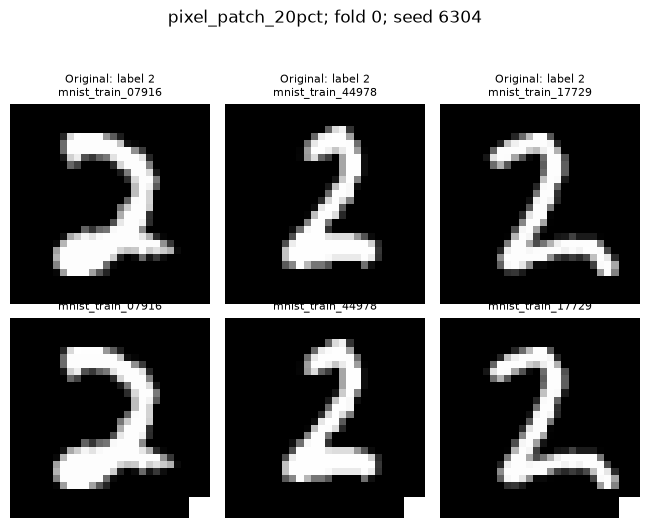

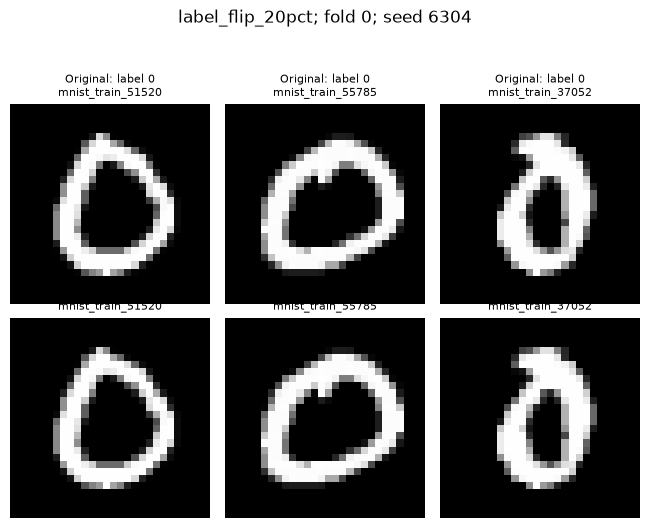

In [53]:
for condition in preview_conditions:
    variant = poison_variants[condition]
    example_indices = np.flatnonzero(variant.is_poisoned)[:3]
    if not len(example_indices):
        print(f"{condition}: no selected records at this dataset size.")
        continue
    figure = plot_examples(clean_training, variant.observed, indices=example_indices, max_examples=3)
    figure.suptitle(f"{condition}; fold {data_config.fold}; seed {POISON_SEED}")
    figure.tight_layout(rect=(0, 0, 1, 0.92))
    poison_figures[f"{condition}_examples"] = figure
    display(figure)
    plt.close(figure)


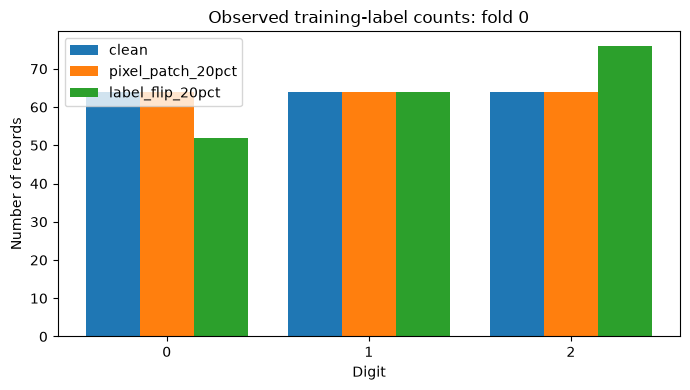

In [54]:
balance_partitions = {"clean": clean_training.labels}
for condition in preview_conditions:
    balance_partitions[condition] = poison_variants[condition].observed.labels
figure = plot_class_balance(balance_partitions)
figure.axes[0].set_title(f"Observed training-label counts: fold {data_config.fold}")
poison_figures["observed_label_counts"] = figure
display(figure)
plt.close(figure)


#### 9.7.1. Check exactly what changed

We prepare two separate poisoning conditions:

| Condition | Image change | Label change |
|---|---|---|
| Pixel patch | Add a white 3-by-3 patch at the bottom-right of selected digit-2 images. | Keep label 2. |
| Label flip | Keep the digit-0 image unchanged. | Change the observed training label from 0 to 2. |

Each row below follows one selected training record through **original image**, **poisoned image**, and **absolute pixel difference**. The orange outline marks the configured patch location; it is only a drawing annotation. The difference panel uses the same 0-255 scale for both attacks, so unchanged images show zero difference.

These detailed figures use `PREVIEW_RATE` from above (20% by default) and show up to three selected records per attack. They are displayed here and included in the Section 9.9 figure exports. Existing preview outputs above are preserved; run this new cell to display the detailed views.


In [ ]:
from src.evaluation.plots import plot_poisoned_examples

# Plot the prepared variants; this cell does not modify images or train models.
for condition in preview_conditions:
    variant = poison_variants[condition]
    if not variant.is_poisoned.any():
        print(f"{condition}: no selected records to display.")
        continue
    figure = plot_poisoned_examples(variant, max_examples=3)
    poison_figures[f"{condition}_pixel_differences"] = figure
    display(figure)
    plt.close(figure)


**How to read these figures:** for the pixel attack, check that differences are confined to the bottom-right patch and that both labels remain 2. A 3-by-3 patch changes at most 9 of the 784 pixels; fewer may change if some pixels already have the patch value. For the label attack, the two images should look identical and the difference panel should show zero changed pixels, while the label changes from 0 to 2.

Validation and test records stay clean. Visible corruption confirms data preparation; its effect after PCA, on classification, and on unlearning still requires later measurement.


### 9.8. Inspect annotations and future forget-set membership

Every saved record retains its original and observed label, sample ID, poison flag/type, and seed. The preview below shows up to three selected records per displayed attack; the saved CSV contains every training record.

The membership table shows both definitions of digit 2 for later analysis. Observed-label class forgetting would include digit-0 records relabeled as 2; original-label forgetting would exclude those digit-0 records. This is a data audit only: no records are deleted and no unlearning is performed.


In [55]:
annotation_preview = pd.concat([
    poison_variants[condition].manifest()
    .loc[poison_variants[condition].is_poisoned].head(3).assign(variant=condition)
    for condition in preview_conditions
], ignore_index=True)
display(annotation_preview)


,sample_id,original_label,observed_label,is_poisoned,poison_type,poison_seed,variant
0,mnist_train_07916,2,2,True,pixel_patch,6304,pixel_patch_20pct
1,mnist_train_44978,2,2,True,pixel_patch,6304,pixel_patch_20pct
2,mnist_train_17729,2,2,True,pixel_patch,6304,pixel_patch_20pct
3,mnist_train_51520,0,2,True,label_flip,6304,label_flip_20pct
4,mnist_train_55785,0,2,True,label_flip,6304,label_flip_20pct
5,mnist_train_37052,0,2,True,label_flip,6304,label_flip_20pct


In [56]:
membership_rows = []
for condition, variant in poison_variants.items():
    original_digit_2 = variant.original.labels == 2
    observed_digit_2 = variant.observed.labels == 2
    membership_rows.append({
        "variant": condition,
        "original_digit_2_records": int(original_digit_2.sum()),
        "observed_digit_2_records": int(observed_digit_2.sum()),
        "relabeled_0_in_observed_digit_2": int(((variant.original.labels == 0) & observed_digit_2).sum()),
    })
poison_membership = pd.DataFrame(membership_rows)
display(poison_membership)


,variant,original_digit_2_records,observed_digit_2_records,relabeled_0_in_observed_digit_2
0,clean,64,64,0
1,pixel_patch_5pct,64,64,0
2,pixel_patch_10pct,64,64,0
3,pixel_patch_20pct,64,64,0
4,label_flip_5pct,64,67,3
5,label_flip_10pct,64,70,6
6,label_flip_20pct,64,76,12


### 9.9. Save annotated datasets and displayed analysis

Executing these cells creates `data/annotated/<condition>_p<percentage>_<fingerprint>/` with `images.npz`, `annotations.csv`, and `metadata.json`. The archive contains observed images, both label versions, stable IDs, and poison flags. Original images remain in `data/raw/mnist.npz` and are recoverable by their sample IDs.

A collection index under `data/annotated/collections/` links all variants to the exact split, settings, and source identity. Matching existing variants are reused; conflicting or incomplete folders raise an error. Displayed tables and figures are saved under `results/tables/poison_preparation_<id>/` and `results/figures/poison_preparation_<id>/`. These are data-preparation artifacts, with no model results.


In [57]:
poison_paths = {}
for condition, variant in poison_variants.items():
    poison_paths[condition] = save_poisoned_dataset(variant, PROJECT_ROOT / "data" / "annotated")

poison_locations = pd.DataFrame([
    {"variant": condition, "directory": path.relative_to(PROJECT_ROOT).as_posix()}
    for condition, path in poison_paths.items()
])
display(poison_locations)


,variant,directory
0,clean,data/annotated/clean_p0_79cf5810e3a64fd1
1,pixel_patch_5pct,data/annotated/pixel_patch_p5_733de5cbe98f8f5d
2,pixel_patch_10pct,data/annotated/pixel_patch_p10_6f461673cde56d10
3,pixel_patch_20pct,data/annotated/pixel_patch_p20_45db150a92e816e9
4,label_flip_5pct,data/annotated/label_flip_p5_b4cecf833c5eb9e3
5,label_flip_10pct,data/annotated/label_flip_p10_e2a4f5980ff1cb78
6,label_flip_20pct,data/annotated/label_flip_p20_be9afbd5a981abab


In [58]:
# Verify saved arrays even when an existing variant directory is reused.
from src.artifacts import load_arrays

for condition, path in poison_paths.items():
    saved = load_arrays(path / "images.npz")
    variant = poison_variants[condition]
    np.testing.assert_array_equal(saved["images"], variant.observed.images)
    np.testing.assert_array_equal(saved["sample_ids"], clean_training.sample_ids)
    np.testing.assert_array_equal(saved["original_labels"], clean_training.labels)
    np.testing.assert_array_equal(saved["observed_labels"], variant.observed.labels)
    np.testing.assert_array_equal(saved["is_poisoned"], variant.is_poisoned)
print("Saved dataset arrays match the prepared variants.")


Saved dataset arrays match the prepared variants.


In [59]:
poison_split_file = save_split_manifest(splits, PROJECT_ROOT / "data" / "splits")
poison_provenance = {
    "stage": "poison_data_preparation", "data_config": asdict(data_config),
    "split_fingerprint": splits.fingerprint(),
    "split_manifest": poison_split_file.relative_to(PROJECT_ROOT).as_posix(),
    "variants": {name: path.relative_to(PROJECT_ROOT).as_posix() for name, path in poison_paths.items()},
    "poison_configs": {name: asdict(variant.config) for name, variant in poison_variants.items()},
    "source_fingerprint": source_fingerprint(), "packages": environment["packages"],
}
poison_collection_id = fingerprint(poison_provenance)[:16]
poison_collection_file = PROJECT_ROOT / "data" / "annotated" / "collections" / f"{poison_collection_id}.json"
save_json(poison_collection_file, poison_provenance)
print("Dataset collection:", poison_collection_file.relative_to(PROJECT_ROOT))


Dataset collection: data\annotated\collections\a21705daefbca067.json


In [60]:
# Include preview settings so exports from different previews have distinct folders.
poison_view = {"collection": poison_collection_file.relative_to(PROJECT_ROOT).as_posix(),
               "preview_rate": PREVIEW_RATE, "max_examples": 3}
poison_view_id = fingerprint(poison_view)[:16]
poison_table_directory = PROJECT_ROOT / "results" / "tables" / f"poison_preparation_{poison_view_id}"
poison_figure_directory = PROJECT_ROOT / "results" / "figures" / f"poison_preparation_{poison_view_id}"
poison_table_directory.mkdir(parents=True, exist_ok=True)
poison_tables = {
    "counts": poison_summary, "changes": poison_changes,
    "label_counts": poison_label_counts.reset_index(), "annotation_preview": annotation_preview,
    "forget_membership": poison_membership, "locations": poison_locations,
}


In [61]:
for name, table in poison_tables.items():
    table.to_csv(poison_table_directory / f"{name}.csv", index=False)
save_json(poison_table_directory / "provenance.json", poison_view)
print("Poison-preparation tables:", poison_table_directory.relative_to(PROJECT_ROOT))


Poison-preparation tables: results\tables\poison_preparation_ea83268d34df2cf3


In [62]:
for name, figure in poison_figures.items():
    save_figure(
        figure, poison_figure_directory / name, source_run_ids=[],
        description=f"Data preparation: {name}; collection {poison_collection_id}; fold {data_config.fold}.",
    )
save_json(poison_figure_directory / "provenance.json", poison_view)
print("Poison-preparation figures:", poison_figure_directory.relative_to(PROJECT_ROOT))


Poison-preparation figures: results\figures\poison_preparation_ea83268d34df2cf3


### 9.10. Interpret the prepared data

- Do the actual counts match the requested rate after rounding, and how much of the entire training partition is affected?
- Do pixel patches preserve labels, and do label flips preserve images while moving counts from digit 0 to digit 2?
- Are any selected patches ineffective? Do small counts limit the distinction between rates?
- How would original-label versus observed-label forgetting change the designated record set?

**Preparation is not a model result.** These checks establish what data was constructed. Damage to classification, quantum robustness, and unlearning outcomes remain questions for later experiments. Poisoned-model preprocessing, training, and evaluation are left for Section 10.


## 10. Poisoned model variants and retraining references - later

Compare poisoned models and their variants against the clean gold reference using matched architecture, records, splits, seeds, and budgets. For later unlearning evaluation, a retained-data retraining reference must exclude exactly the records designated for forgetting. State whether preprocessing is refitted or frozen.

## 11. Guided and uniform unlearning - later

Construct fixed model-derived targets and training-only anchors. Compare guided/uniform targets, retained performance, digit-2 confidence/recall, and agreement with matched retraining before/after unlearning.

## 12. Repeated simulator experiments - later
### 12.1. Folds, controls, and ablations

Keep the project seed fixed at **6304** for all current runs. Compare paired conditions across folds, then add shuffle controls and target/anchor/regularization comparisons. Variation across folds does not establish uncertainty across independent seeds. Multi-seed studies remain deferred unless the protocol is changed explicitly.


### 12.2. Device noise and shots

Keep data poisoning and device noise as separate factors. Record the noise model, shot budget, and whether weights are fixed or retrained.

## 13. Optional IBM hardware evaluation - later

Keep hardware disabled until access and the evaluation plan are available. Use saved parameters for a small evaluation and record device, transpilation, shots, and job IDs.

## 14. Phase 1 conclusions and report - later

Combine paired results, uncertainty, resources, limitations, and the falsifier. Report evidence for robustness, failure, or an inconclusive outcome.

## 15. Phase 2 - deferred

Consider new targets, constraints, or selective sample-level forgetting after completing Phase 1.